#Práctica 8 Equipo #2

Librerías 

In [68]:
import os, cv2, numpy as np, matplotlib.pyplot as plt
plt.rcParams['figure.dpi']=110

UTILIDADES \
Funciones auxiliares pequeñas para mostrar imágenes, normalizar inputs y guardar resultados.\
Esta sección se ejecuta una vez y se reutiliza en las demás celdas. Muestra una lista de imágenes en una fila con títulos.\
Uso: show([img1,img2], ['t1','t2'], suptitle='Comparación')

In [69]:
def show(imgs, titles=None, cmap='gray', figsize=(12,4), suptitle=None):
    n=len(imgs); fig,axes=plt.subplots(1,n,figsize=figsize);
    if n==1: axes=[axes]
    if suptitle: fig.suptitle(suptitle)
    for ax,im,t in zip(axes,imgs,(titles or [""]*n)):
        ax.imshow(im, cmap=cmap); ax.set_title(t); ax.axis('off')
    plt.show()

Normaliza una imagen NumPy a float32 en rango [0,1] y la convierte a gris si tiene 3 canales.\
Convierte una imagen (np.ndarray) a float32 en [0,1] y a escala de grises si aplica.

In [70]:
def to_float01(img):
    img=np.asarray(img).astype(np.float32)
    if img.max()>1.0: img/=255.0
    if img.ndim==3: img=cv2.cvtColor(img,cv2.COLOR_BGR2GRAY)
    return img

Guarda una imagen en disco tomando como entrada una imagen en [0,1]

In [71]:
def save(path,img): cv2.imwrite(path, np.clip((img*255).astype(np.uint8),0,255))

CARGA DE IMÁGENES 
Lee desde disco dos imágenes previstas para el ejercicio. Si no existen, imprime aviso.
Modifica img_path1/img_path2 para usar tus archivos.

In [72]:
img_path1='radiografia.jpg'; img_path2='corte.jpg'

Cargar en escala de grises con OpenCV

In [73]:
img1 = cv2.imread(img_path1, cv2.IMREAD_GRAYSCALE) if os.path.exists(img_path1) else None
img2 = cv2.imread(img_path2, cv2.IMREAD_GRAYSCALE) if os.path.exists(img_path2) else None
if img1 is None or img2 is None:
    print('AVISO: coloque radiografia.jpg y corte.jpg en la carpeta o actualice las rutas')


Normalizar imágenes cargadas a float [0,1]

In [74]:
if img1 is not None: img1 = to_float01(img1)
if img2 is not None: img2 = to_float01(img2)

Mostrar originales si se cargaron

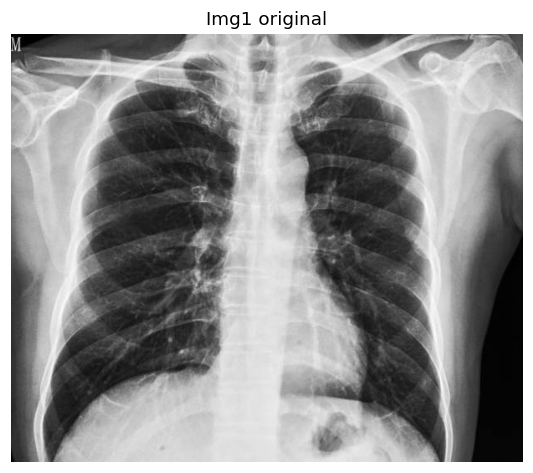

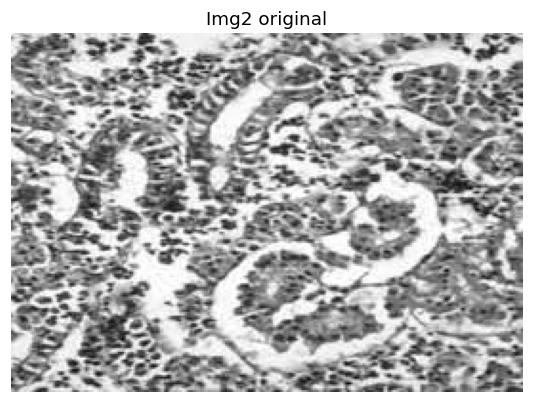

In [75]:
if img1 is not None: show([img1],['Img1 original'],figsize=(6,6))
if img2 is not None: show([img2],['Img2 original'],figsize=(6,6))

PARTE I — FILTROS ESPACIALES 
Implementa filtros de suavizado (media, gaussiano, mediana) con kernels 3x3,5x5,11x11, detectores de borde (Sobel x/y, Laplaciano, Kirsch) y máscaras personalizadas.

In [76]:
def smoothing(img):
    u=(img*255).astype(np.uint8)
    sizes=[3,5,11]
    out={}
    for k in sizes:
        out[f'media_{k}']=cv2.blur(u,(k,k)).astype(np.float32)/255.0
        out[f'gauss_{k}']=cv2.GaussianBlur(u,(k,k),0).astype(np.float32)/255.0
        out[f'mediana_{k}']=cv2.medianBlur(u,k).astype(np.float32)/255.0
    return out

Detectores de borde y Kirsch 
Calcula Sobel en x/y, magnitud, Laplaciano y la respuesta máxima de las 8 máscaras Kirsch.

In [77]:
def edges(img):
    u=(img*255).astype(np.uint8)
    sx=cv2.Sobel(u,cv2.CV_64F,1,0,ksize=3); sy=cv2.Sobel(u,cv2.CV_64F,0,1,ksize=3)
    lap=np.abs(cv2.Laplacian(u,cv2.CV_64F))
    sobmag=np.hypot(sx,sy)
    # Kirsch: 8 máscaras direccionales
    K=[np.array([[5,5,5],[-3,0,-3],[-3,-3,-3]],np.float32),
        np.array([[5,5,-3],[5,0,-3],[-3,-3,-3]],np.float32),
        np.array([[5,-3,-3],[5,0,-3],[5,-3,-3]],np.float32),
        np.array([[-3,-3,-3],[5,0,-3],[5,5,-3]],np.float32),
        np.array([[-3,-3,-3],[-3,0,-3],[5,5,5]],np.float32),
        np.array([[-3,-3,-3],[-3,0,5],[-3,5,5]],np.float32),
        np.array([[-3,-3,5],[-3,0,5],[-3,-3,5]],np.float32),
        np.array([[-3,5,5],[-3,0,5],[-3,-3,-3]],np.float32)]
    kr=[cv2.filter2D(u.astype(np.float32),-1,k) for k in K]
    kir=np.max(np.stack(kr),axis=0)
    def norm(a): a=a-a.min(); return a/(a.max() if a.max()!=0 else 1)
    return {'sobelx':norm(np.abs(sx)),'sobely':norm(np.abs(sy)),'sobel_mag':norm(sobmag),'lap':norm(lap),'kirsch':norm(kir)}

Aplicar kernel personalizado (Descripción)
 Permite probar máscaras propias de realce o detección.

In [78]:
def apply_kernel(img,kernel):
    u=(img*255).astype(np.uint8)
    r=cv2.filter2D(u.astype(np.float32),-1,kernel)
    r=r-r.min(); return r/(r.max() if r.max()!=0 else 1)

Ejecutar Parte I sobre img1 si está disponible

In [79]:
if img1 is not None:
    sm=smoothing(img1)

Mostrar comparativa de suavizados (3 ejemplos representativos)

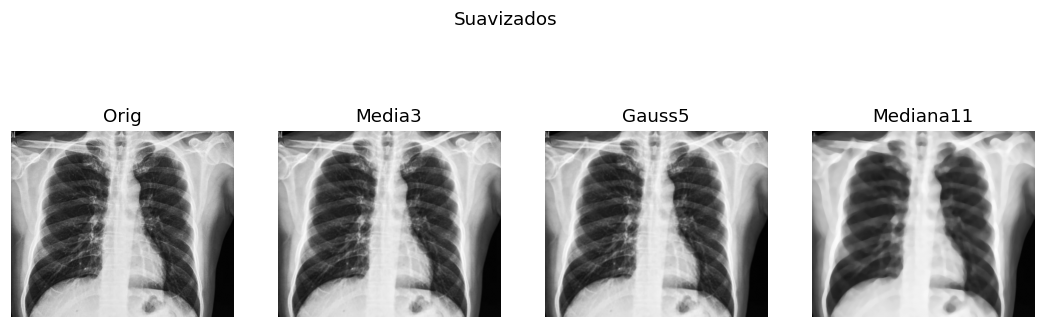

In [80]:
show([img1,sm['media_3'],sm['gauss_5'],sm['mediana_11']], ['Orig','Media3','Gauss5','Mediana11'], suptitle='Suavizados')
ed=edges(img1)

Mostrar Sobel y otros detectores

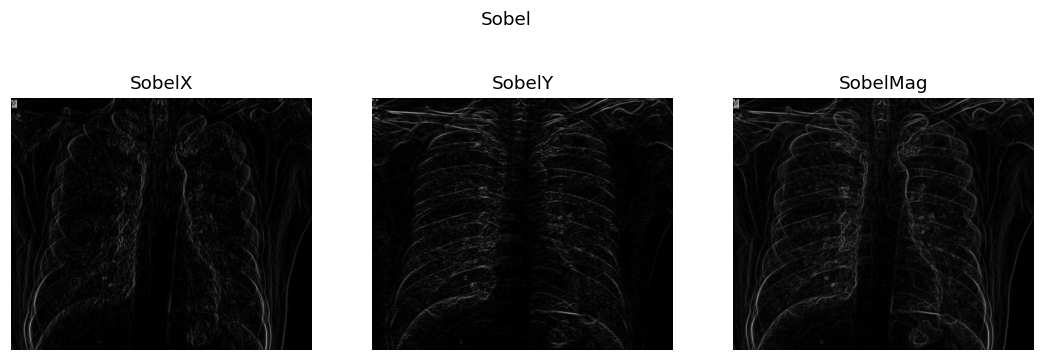

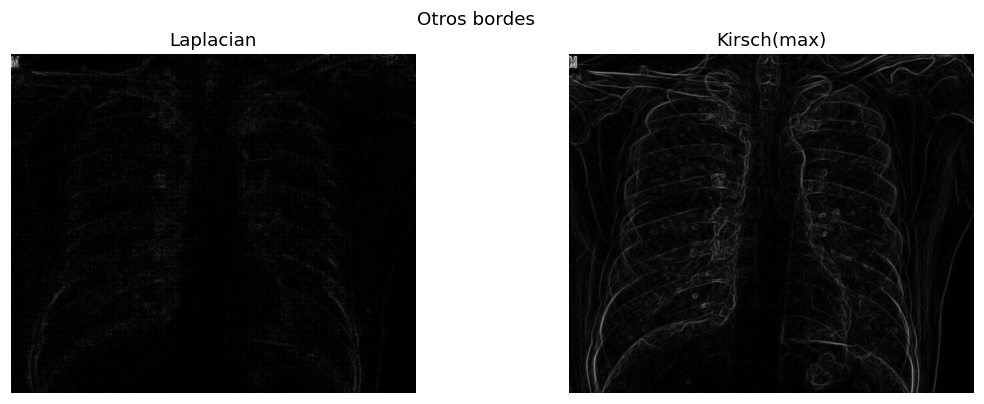

In [81]:
show([ed['sobelx'],ed['sobely'],ed['sobel_mag']],['SobelX','SobelY','SobelMag'], suptitle='Sobel')
show([ed['lap'],ed['kirsch']],['Laplacian','Kirsch(max)'], suptitle='Otros bordes')

Máscaras personalizadas: ejemplo de sharpen y énfasis vertical

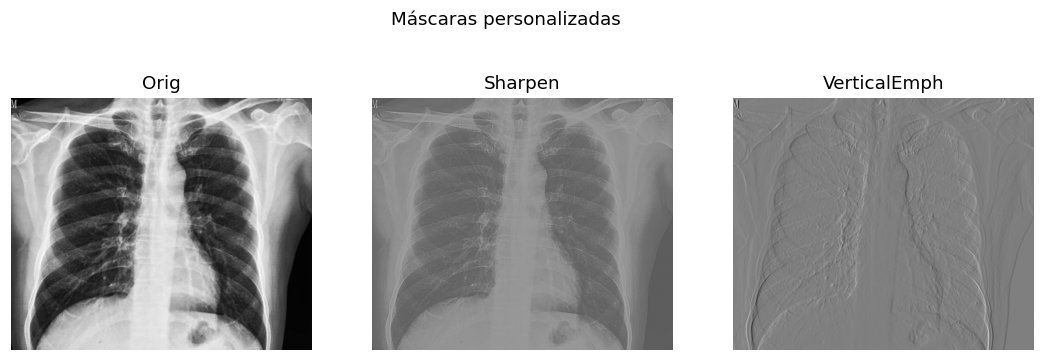

In [82]:
custom_sh=np.array([[0,-1,0],[-1,5,-1],[0,-1,0]],np.float32)
custom_vert=np.array([[-1,0,1],[-2,0,2],[-1,0,1]],np.float32)
show([img1,apply_kernel(img1,custom_sh),apply_kernel(img1,custom_vert)],['Orig','Sharpen','VerticalEmph'], suptitle='Máscaras personalizadas')

PARTE II — FILTROS EN FRECUENCIA 
Transformada de Fourier con NumPy, construcción de máscaras (círculo, anillo, cruz) y aplicación de filtros pasa-bajas y pasa-altas con visualización del espectro.

In [83]:
def fft(img):
    F=np.fft.fftshift(np.fft.fft2(img)); M=np.log1p(np.abs(F)); M=(M-M.min())/(M.max()-M.min() if M.max()!=M.min() else 1)
    return F,M
def ifft(Fshift):
    f=np.fft.ifft2(np.fft.ifftshift(Fshift)); r=np.real(f); r=r-r.min(); return r/(r.max() if r.max()!=0 else 1)

Máscaras: círculo, anillo y cruz (descripción breve en cada función)

In [84]:
def circ_mask(shape,r):
    rows,cols=shape; cy, cx=rows//2, cols//2; Y,X=np.ogrid[:rows,:cols]; m=((Y-cy)**2+(X-cx)**2)<=r*r; return m.astype(np.float32)

def ring_mask(shape,ri,ro):
    rows,cols=shape; cy, cx=rows//2, cols//2; Y,X=np.ogrid[:rows,:cols]; d=np.sqrt((Y-cy)**2+(X-cx)**2); m=(d>=ri)&(d<=ro); return m.astype(np.float32)

def cross_mask(shape,th=5):
    rows,cols=shape; cy, cx=rows//2, cols//2; m=np.zeros(shape,np.float32); m[cy-th:cy+th+1,:]=1; m[:,cx-th:cx+th+1]=1; return m

Aplicación genérica de máscara en frecuencia (devuelve imagen filtrada y espectros)

In [85]:
def apply_freq(img,mask):
    F,M=fft(img); Fm=F*mask; imgb=ifft(Fm); Mm=np.log1p(np.abs(Fm)); Mm=(Mm-Mm.min())/(Mm.max()-Mm.min() if Mm.max()!=Mm.min() else 1)
    return imgb, M, Mm, mask

Ejecutar Parte II sobre img1 (pasa-bajas con radios, y pasa-altas con varias configuraciones)

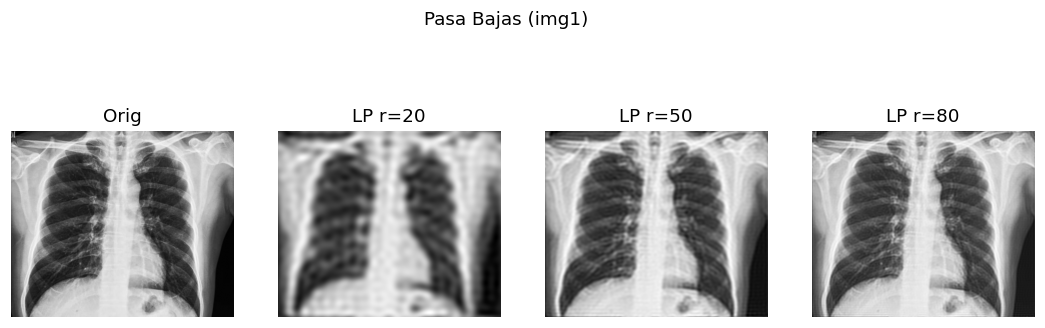

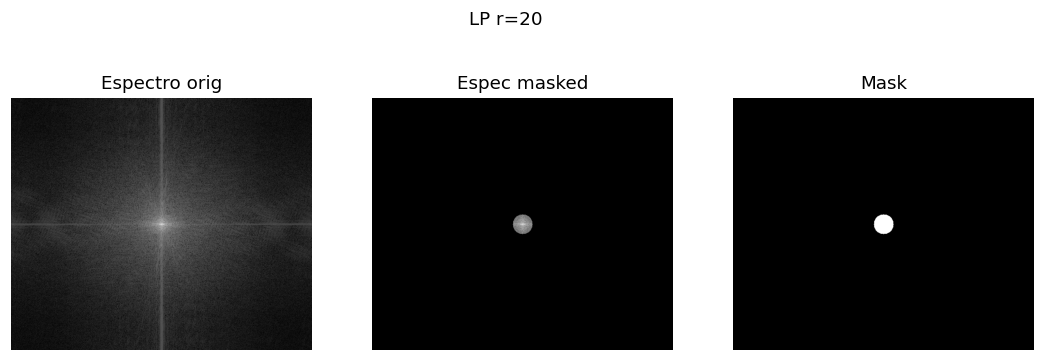

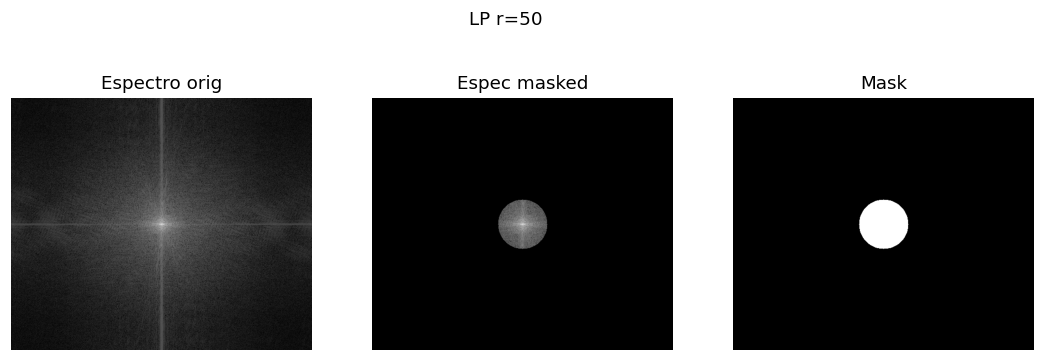

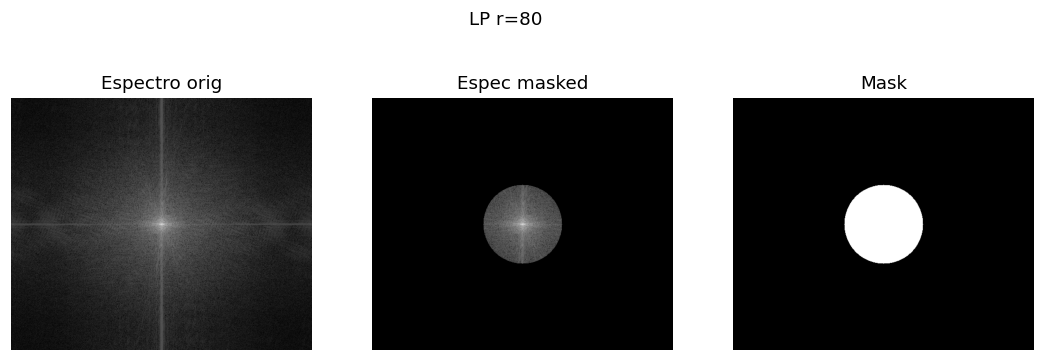

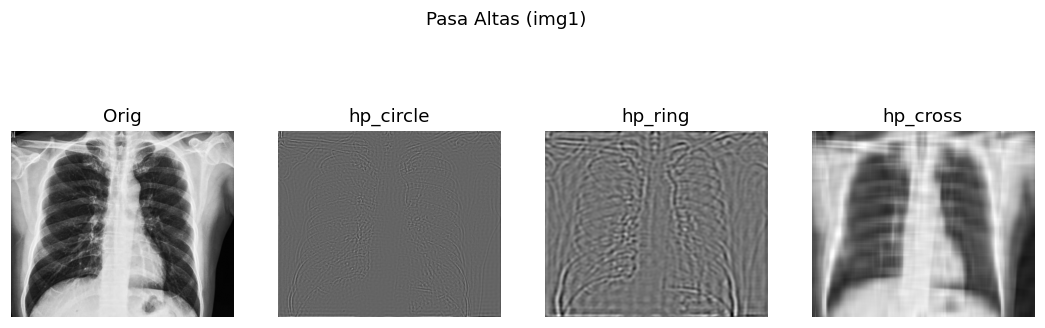

In [86]:
if img1 is not None:
    rows,cols=img1.shape; radios=[20,50,80]; radios=[min(max(3,r),min(rows,cols)//2-1) for r in radios]
    lp=[]
    for r in radios:
        imgb,M,Mm,mask=apply_freq(img1,circ_mask(img1.shape,r)); lp.append((r,imgb,M,Mm,mask))
    show([img1]+[x[1] for x in lp],['Orig']+[f'LP r={x[0]}' for x in lp], suptitle='Pasa Bajas (img1)')
    for r,imgb,M,Mm,mask in lp: show([M,Mm,mask],['Espectro orig','Espec masked','Mask'], suptitle=f'LP r={r}')
    hp_cfg={'hp_circle':1-circ_mask(img1.shape,radios[1]),'hp_ring':ring_mask(img1.shape,radios[0],radios[1]),'hp_cross':cross_mask(img1.shape,5)}
    hp_res={k:apply_freq(img1,v) for k,v in hp_cfg.items()}
    show([img1]+[hp_res[k][0] for k in hp_res],['Orig']+list(hp_res.keys()), suptitle='Pasa Altas (img1)')

Repetir Parte II para la segunda imagen

Aplicando filtros en frecuencia a la segunda imagen


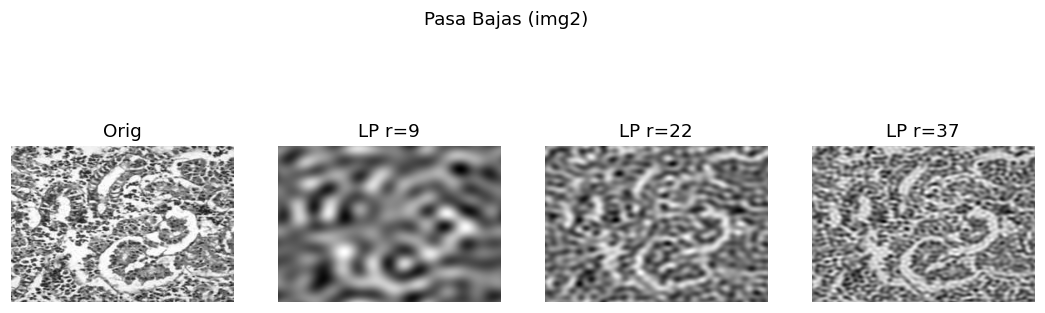

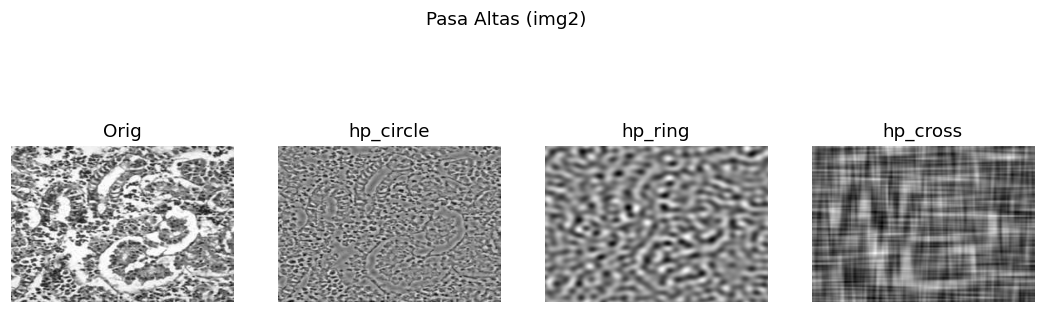

In [87]:
if img2 is not None:
    print('Aplicando filtros en frecuencia a la segunda imagen')
    rows2,cols2=img2.shape; radios2=[int(min(rows2,cols2)*0.05),int(min(rows2,cols2)*0.12),int(min(rows2,cols2)*0.2)]
    lp2=[]
    for r in radios2:
        imgb,M,Mm,mask=apply_freq(img2,circ_mask(img2.shape,r)); lp2.append((r,imgb,M,Mm,mask))
    show([img2]+[x[1] for x in lp2],['Orig']+[f'LP r={x[0]}' for x in lp2], suptitle='Pasa Bajas (img2)')
    hp2={'hp_circle':1-circ_mask(img2.shape,radios2[1]),'hp_ring':ring_mask(img2.shape,radios2[0],radios2[1]),'hp_cross':cross_mask(img2.shape,3)}
    hp2res={k:apply_freq(img2,v) for k,v in hp2.items()}
    show([img2]+[hp2res[k][0] for k in hp2res],['Orig']+list(hp2res.keys()), suptitle='Pasa Altas (img2)')